# No-Churn Telecom - Customer Churn Prediction

**Client:** No-Churn Telecom | **Category:** Telecom - Churn ML | **Ref:** PM-PR-0017

## 1. Context of the model

The telecom market is very competitive because of new players. Even after reducing tariffs and promoting offers, No-Churn's **churn rate (customers moving to competitors) is above 10%**. Keeping an existing customer costs less than winning a new one, so the company wants to use Machine Learning to find out **who may leave and why**.

**Project goals**
1. Understand the variables that influence customers to migrate (**churn drivers**).
2. Create **churn risk scores** that can drive retention campaigns.
3. Create a new predicted variable **`CHURN_FLAG`** (YES = 1 / NO = 0) so email campaigns with offers can target Churn-YES customers, and customer care can give them extra attention (priority tickets, quick resolution).

**Type of problem:** supervised **binary classification** (target = `churn`, 1 = customer left, 0 = stayed).

**Models used:** Logistic Regression, KNN, Random Forest, XGBClassifier.

**Metrics:** only ~10% of customers churn, so accuracy is misleading (predicting "nobody churns" is already ~90% accurate). I focus on **ROC-AUC, PR-AUC, Recall, Precision and F1**.

## 2. Load the dataset

In [4]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import quote_plus

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [5]:
from sqlalchemy import create_engine

# Connection details
host = "18.136.157.135"
user = "dm_team3"
password = quote_plus("DM!$!Team!27@9!20&")   # URL-encode since it has special characters
database = "project_telecom"

engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}/{database}")

# Confirm the table is there
tables = pd.read_sql("SHOW TABLES;", engine)
print(tables)

df = pd.read_sql("SELECT * FROM telecom_churn_data;", engine)
print("Loaded", len(df), "rows from SQL")
df.head()

  Tables_in_project_telecom
0        telecom_churn_data
Loaded 243553 rows from SQL


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


## 3. Initial basic checks

In [7]:
df.columns = df.columns.str.strip().str.lower()   # tidy column names

print("Shape:", df.shape)
df.info()

Shape: (243553, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   customer_id           243553 non-null  int64 
 1   telecom_partner       243553 non-null  object
 2   gender                243553 non-null  object
 3   age                   243553 non-null  int64 
 4   state                 243553 non-null  object
 5   city                  243553 non-null  object
 6   pincode               243553 non-null  int64 
 7   date_of_registration  243553 non-null  object
 8   num_dependents        243553 non-null  int64 
 9   estimated_salary      243553 non-null  int64 
 10  calls_made            243553 non-null  int64 
 11  sms_sent              243553 non-null  int64 
 12  data_used             243553 non-null  int64 
 13  churn                 243553 non-null  int64 
dtypes: int64(9), object(5)
memory usage: 26.0+ MB


In [8]:
display(df.describe().T.round(2))
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer_id:", df["customer_id"].duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
customer_id,243553.0,121777.00,70307.84,1.0,60889.0,121777.0,182665.0,243553.0
age,243553.0,46.08,16.44,18.0,32.0,46.0,60.0,74.0
pincode,243553.0,549501.27,259808.86,100006.0,324586.0,548112.0,774994.0,999987.0
num_dependents,243553.0,2.00,1.41,0.0,1.0,2.0,3.0,4.0
estimated_salary,243553.0,85021.14,37508.96,20000.0,52585.0,84990.0,117488.0,149999.0
calls_made,243553.0,49.01,29.45,-10.0,24.0,49.0,74.0,108.0
sms_sent,243553.0,23.95,14.73,-5.0,11.0,24.0,36.0,53.0
data_used,243553.0,4993.19,2942.02,-987.0,2490.0,4987.0,7493.0,10991.0
churn,243553.0,0.20,0.40,0.0,0.0,0.0,0.0,1.0


Missing values:
 customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
dtype: int64

Duplicate rows: 0
Duplicate customer_id: 0


In [9]:
# Convert target to 0/1 (handles Yes/No, True/False and 0/1)
print(df["churn"].value_counts(dropna=False))
if df["churn"].dtype == "object":
    df["churn"] = df["churn"].str.strip().str.lower().str.rstrip(".").map({"yes": 1, "no": 0, "true": 1, "false": 0, "1": 1, "0": 0})
df["churn"] = df["churn"].astype(int)
print("\nChurn rate: {:.2%}".format(df["churn"].mean()))

# Data-quality check: negative or infinite values in numeric columns
num_cols = ["age", "num_dependents", "estimated_salary", "calls_made", "sms_sent", "data_used"]
nums = df[num_cols].apply(pd.to_numeric, errors="coerce")
print("\nNegative values per column:\n", (nums < 0).sum())
print("\nInfinite values per column:\n", np.isinf(nums).sum())
print("\nUnique values:\n", df.nunique())

churn
0    194726
1     48827
Name: count, dtype: int64

Churn rate: 20.05%

Negative values per column:
 age                    0
num_dependents         0
estimated_salary       0
calls_made          6713
sms_sent            7375
data_used           6050
dtype: int64

Infinite values per column:
 age                 0
num_dependents      0
estimated_salary    0
calls_made          0
sms_sent            0
data_used           0
dtype: int64

Unique values:
 customer_id             243553
telecom_partner              4
gender                       2
age                         57
state                       28
city                         6
pincode                 213442
date_of_registration      1220
num_dependents               5
estimated_salary        110032
calls_made                 119
sms_sent                    59
data_used                11837
churn                        2
dtype: int64


**What to look at here:** shape, data types, missing values, duplicates, the churn rate, and any negative/infinite values (they are impossible for ages, calls, salary etc. and will be fixed in step 5). `customer_id` and `pincode` are identifiers, not useful predictors.

## 4. EDA (Exploratory Data Analysis)

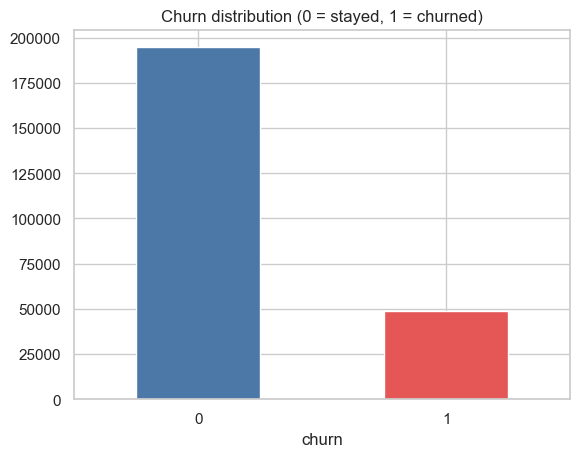

In [12]:
# Target distribution
df["churn"].value_counts().plot(kind="bar", color=["#4C78A8", "#E45756"], rot=0)
plt.title("Churn distribution (0 = stayed, 1 = churned)")
plt.show()

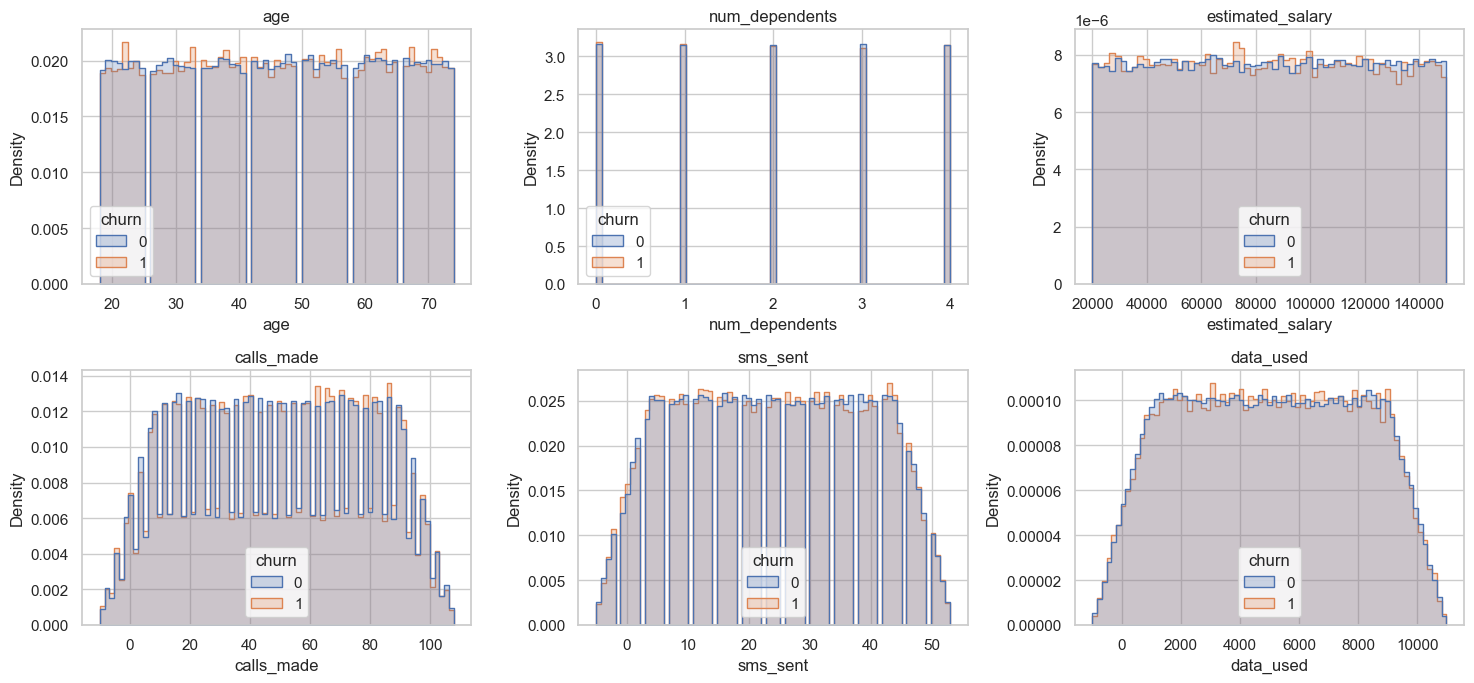

churn,0,1
age,46.07,46.11
num_dependents,2.00,1.99
estimated_salary,85083.73,84771.53
calls_made,48.99,49.11
sms_sent,23.97,23.86
data_used,4992.11,4997.49


In [13]:
# Distribution of numeric columns (churned vs stayed)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue="churn", element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Average of each numeric column for churned vs stayed customers
display(df.groupby("churn")[num_cols].mean().T.round(2))

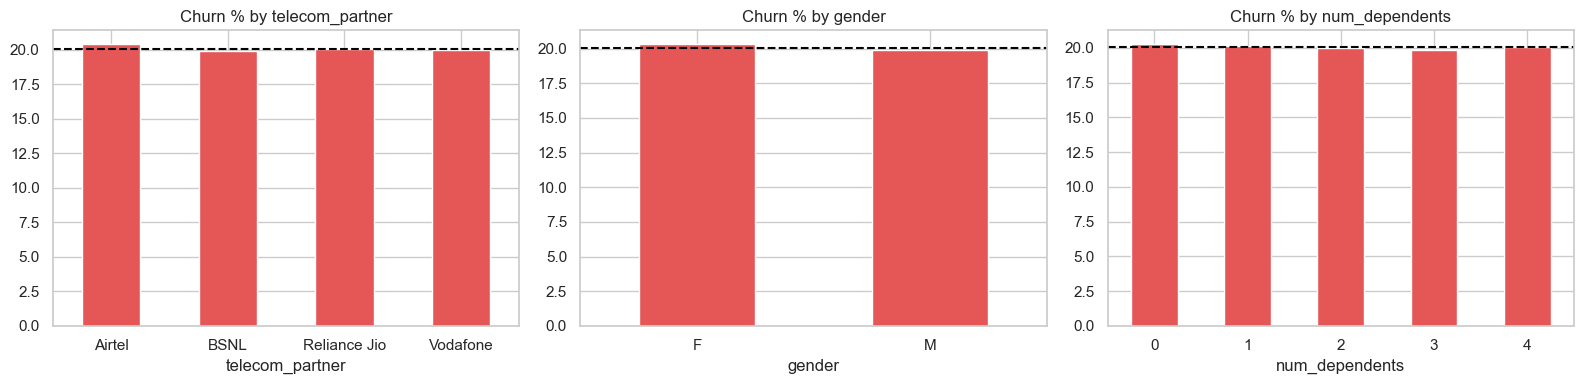

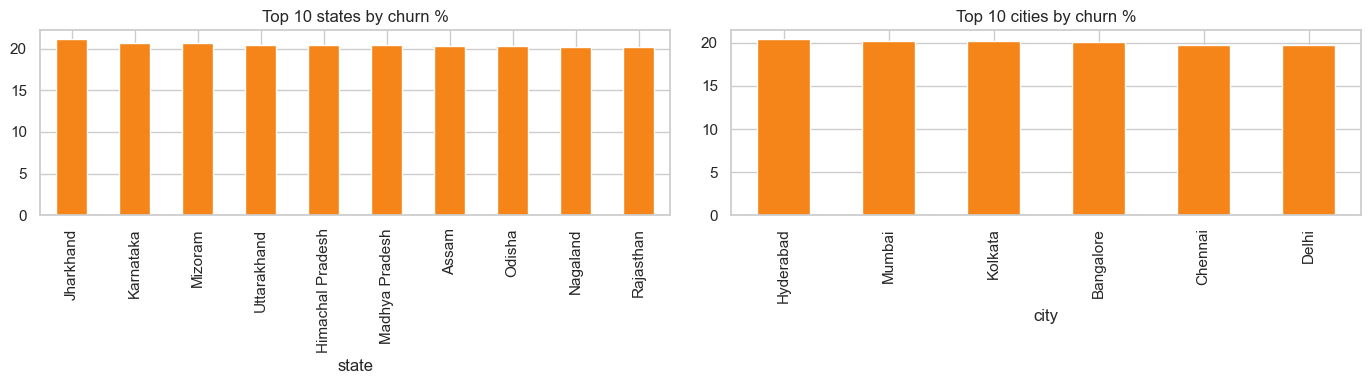

In [14]:
# Churn rate (%) for each category
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["telecom_partner", "gender", "num_dependents"]):
    (df.groupby(col)["churn"].mean() * 100).plot(kind="bar", ax=ax, color="#E45756", rot=0)
    ax.axhline(df["churn"].mean() * 100, color="black", linestyle="--")
    ax.set_title("Churn % by " + col)
plt.tight_layout()
plt.show()

# Top 10 states and cities by churn rate
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
(df.groupby("state")["churn"].mean() * 100).sort_values(ascending=False).head(10).plot(kind="bar", ax=axes[0], color="#F58518")
axes[0].set_title("Top 10 states by churn %")
(df.groupby("city")["churn"].mean() * 100).sort_values(ascending=False).head(10).plot(kind="bar", ax=axes[1], color="#F58518")
axes[1].set_title("Top 10 cities by churn %")
plt.tight_layout()
plt.show()

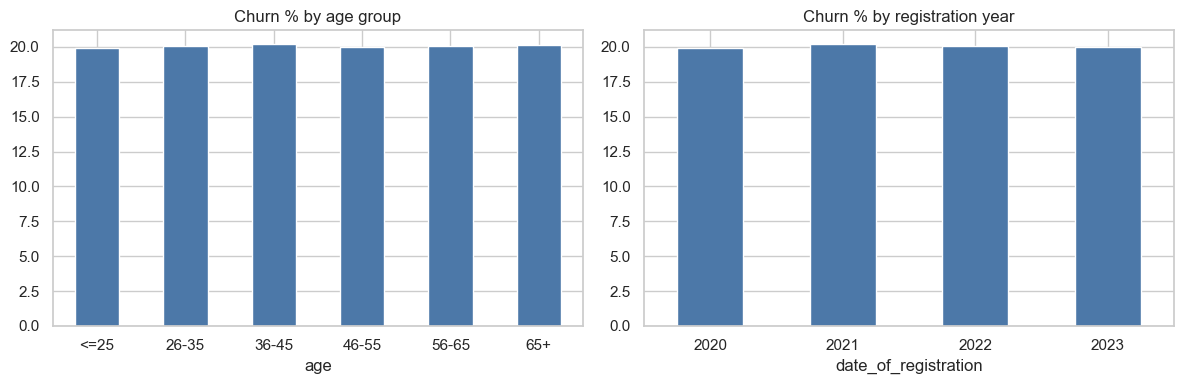

In [15]:
# Churn rate by age group and by registration year
age_group = pd.cut(df["age"], [0, 25, 35, 45, 55, 65, 120], labels=["<=25", "26-35", "36-45", "46-55", "56-65", "65+"])
reg_year = pd.to_datetime(df["date_of_registration"], errors="coerce").dt.year

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(df.groupby(age_group)["churn"].mean() * 100).plot(kind="bar", ax=axes[0], color="#4C78A8", rot=0)
axes[0].set_title("Churn % by age group")
(df.groupby(reg_year)["churn"].mean() * 100).plot(kind="bar", ax=axes[1], color="#4C78A8", rot=0)
axes[1].set_title("Churn % by registration year")
plt.tight_layout()
plt.show()

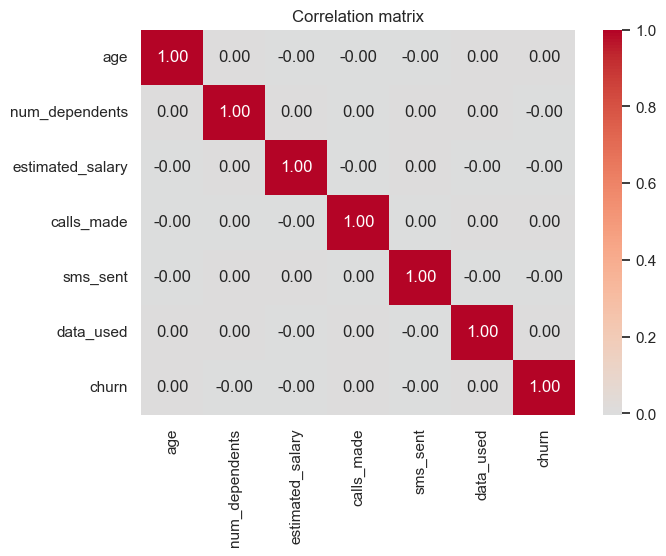

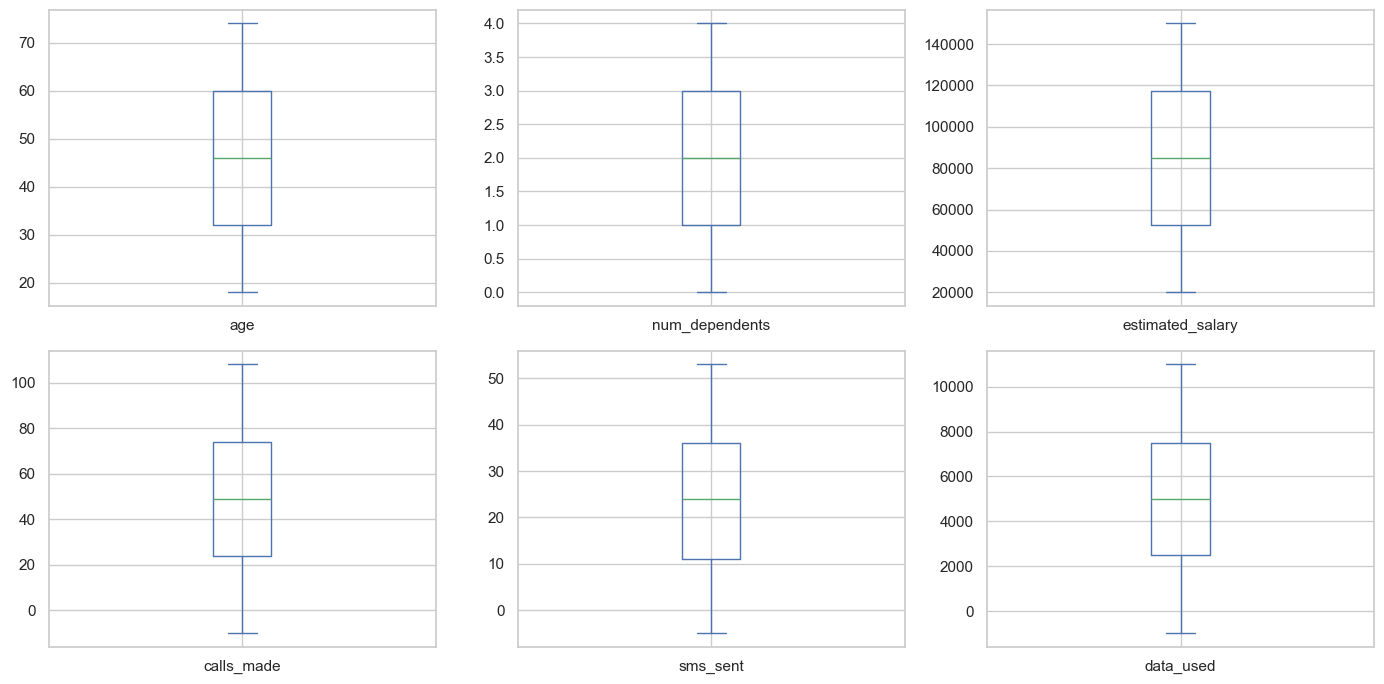

In [16]:
# Correlation heatmap and outlier boxplots
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + ["churn"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

df[num_cols].plot(kind="box", subplots=True, layout=(2, 3), figsize=(14, 7), sharex=False, sharey=False)
plt.tight_layout()
plt.show()

## 5. Data preprocessing and feature engineering

In [18]:
data = df.copy()
data["date_of_registration"] = pd.to_datetime(data["date_of_registration"], errors="coerce")

# 1) Clean wrong values: non-numeric, infinite or negative values -> missing (NaN). They are filled later in the pipeline.
data[num_cols] = data[num_cols].apply(pd.to_numeric, errors="coerce")
data[num_cols] = data[num_cols].replace([np.inf, -np.inf], np.nan)
for col in num_cols:
    data.loc[data[col] < 0, col] = np.nan

# 2) New features
data["tenure_months"] = (data["date_of_registration"].max() - data["date_of_registration"]).dt.days / 30.44
data["total_activity"] = data["calls_made"] + data["sms_sent"]
data["salary_per_dependent"] = data["estimated_salary"] / (data["num_dependents"] + 1)

# 3) Drop identifiers and the raw date
data = data.drop(columns=["customer_id", "pincode", "date_of_registration"])

# 4) Drop city / state if they have too many categories
cat_cols = ["telecom_partner", "gender", "state", "city"]
for col in ["state", "city"]:
    if data[col].nunique() > 50:
        print("Dropping", col, "- too many categories")
        data = data.drop(columns=col)
        cat_cols.remove(col)

num_features = num_cols + ["tenure_months", "total_activity", "salary_per_dependent"]
print("Missing values after cleaning:\n", data[num_features].isnull().sum())

X = data.drop(columns="churn")
y = data["churn"]
print("\nX shape:", X.shape)
X.head()

Missing values after cleaning:
 age                         0
num_dependents              0
estimated_salary            0
calls_made               6713
sms_sent                 7375
data_used                6050
tenure_months               0
total_activity          13886
salary_per_dependent        0
dtype: int64

X shape: (243553, 13)


,telecom_partner,gender,age,state,city,num_dependents,estimated_salary,calls_made,sms_sent,data_used,tenure_months,total_activity,salary_per_dependent
0,Reliance Jio,F,25.0,Karnataka,Kolkata,4.0,124962.0,44.0,45.0,NaN,40.045992,89.0,24992.400000
1,Reliance Jio,F,55.0,Mizoram,Mumbai,2.0,130556.0,62.0,39.0,5973.0,40.045992,101.0,43518.666667
2,Vodafone,F,57.0,Arunachal Pradesh,Delhi,0.0,148828.0,49.0,24.0,193.0,40.045992,73.0,148828.000000
3,BSNL,M,46.0,Tamil Nadu,Kolkata,1.0,38722.0,80.0,25.0,9377.0,40.045992,105.0,19361.000000
4,BSNL,F,26.0,Tripura,Delhi,2.0,55098.0,78.0,15.0,1393.0,40.045992,93.0,18366.000000


**What was done**
* Negative / infinite / non-numeric values set to missing (the cause of the earlier *"Input X contains infinity"* error); missing values are filled with the median inside the pipeline.
* New features: `tenure_months` (how long the customer has been registered), `total_activity` (calls + SMS), `salary_per_dependent`.
* Dropped `customer_id`, `pincode` (identifiers) and the raw date.

## 6. Outlier capping (IQR method)

In [21]:
# IQR rule: lower = Q1 - 1.5*IQR, upper = Q3 + 1.5*IQR
q1 = X[num_features].quantile(0.25)
q3 = X[num_features].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_count = ((X[num_features] < lower) | (X[num_features] > upper)).sum()
display(pd.DataFrame({"lower": lower, "upper": upper, "n_outliers": outlier_count,
                      "pct": (outlier_count / len(X) * 100).round(2)}).round(2))

,lower,upper,n_outliers,pct
age,-10.00,102.00,0,0.00
num_dependents,-2.00,6.00,0,0.00
estimated_salary,-44769.50,214842.50,0,0.00
calls_made,-47.50,148.50,0,0.00
sms_sent,-23.00,73.00,0,0.00
data_used,-4648.00,14880.00,0,0.00
tenure_months,-20.04,60.12,0,0.00
total_activity,-22.50,173.50,0,0.00
salary_per_dependent,-28604.17,93957.17,21097,8.66


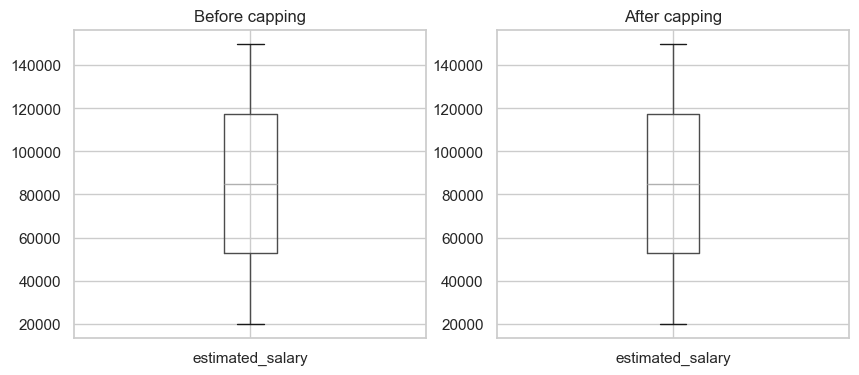

In [22]:
# Capping is needed where the table shows outliers. To avoid data leakage, the limits are calculated on the TRAIN data
# only (after the split in step 8) and then applied to both train and test using this function.
def cap_outliers(data, lower, upper):
    return data.clip(lower=lower, upper=upper, axis=1)

# Example on 'estimated_salary'
capped_example = cap_outliers(X[num_features], lower, upper)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
X[["estimated_salary"]].boxplot(ax=axes[0]); axes[0].set_title("Before capping")
capped_example[["estimated_salary"]].boxplot(ax=axes[1]); axes[1].set_title("After capping")
plt.show()

## 7. Column transformer

In [24]:
# Numeric: fill missing with median, then scale | Categorical: fill missing with most frequent, then one-hot encode
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([("num", numeric_pipe, num_features),
                                  ("cat", categorical_pipe, cat_cols)])
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'num_dependents', 'estimated_salary',
                                  'calls_made', 'sms_sent', 'data_used',
                                  'tenure_months', 'total_activity',
                                  'salary_per_dependent']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['telecom_partner', 'gender', 'state',
                                  'city'])])

## 8. Splitting and model creation

In [26]:
# 80% train / 20% test, keeping the same churn % in both (stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train: {:.2%} | test: {:.2%}".format(y_train.mean(), y_test.mean()))

# Cap outliers: limits learnt from TRAIN only
q1 = X_train[num_features].quantile(0.25)
q3 = X_train[num_features].quantile(0.75)
lower = q1 - 1.5 * (q3 - q1)
upper = q3 + 1.5 * (q3 - q1)

X_train = X_train.copy()
X_test = X_test.copy()
X_train[num_features] = cap_outliers(X_train[num_features], lower, upper)
X_test[num_features] = cap_outliers(X_test[num_features], lower, upper)

Train: (194842, 13) | Test: (48711, 13)
Churn rate train: 20.05% | test: 20.05%


In [27]:
# Weight for the minority class (churners)
ratio = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=20,
                                            class_weight="balanced", n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, scale_pos_weight=ratio,
                             eval_metric="logloss", random_state=42),
}
list(models)

['Logistic Regression', 'KNN', 'Random Forest', 'XGBoost']

## 9. Train Logistic Regression, KNN, Random Forest and XGBoost

In [29]:
results = []
pipelines = {}
probas = {}

for name, model in models.items():
    # clone() gives every model its own copy of the preprocessor
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])
    pipe.fit(X_train, y_train)

    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)

    results.append({"Model": name,
                    "ROC-AUC": roc_auc_score(y_test, proba),
                    "PR-AUC": average_precision_score(y_test, proba),
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred, zero_division=0),
                    "Recall": recall_score(y_test, pred),
                    "F1": f1_score(y_test, pred)})
    pipelines[name] = pipe
    probas[name] = proba
    print("done:", name)

done: Logistic Regression
done: KNN
done: Random Forest
done: XGBoost


## 10. Model comparison and best model

In [31]:
comparison = pd.DataFrame(results).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(comparison.round(4))

best_name = comparison.index[0]
best_pipe = pipelines[best_name]
print("Best model (highest ROC-AUC on the test set):", best_name)
print("Reference: a random model has ROC-AUC 0.50 and PR-AUC = churn rate = {:.3f}".format(y_test.mean()))

,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
Model,,,,,,
Logistic Regression,0.5061,0.2049,0.5076,0.2031,0.4980,0.2885
Random Forest,0.5029,0.2041,0.5681,0.2022,0.3918,0.2667
XGBoost,0.5012,0.2001,0.5119,0.2015,0.4844,0.2846
KNN,0.4988,0.2004,0.7994,0.3500,0.0007,0.0014


Best model (highest ROC-AUC on the test set): Logistic Regression
Reference: a random model has ROC-AUC 0.50 and PR-AUC = churn rate = 0.200


**How to read the table:** compare models mainly on **ROC-AUC and PR-AUC** (they do not depend on a cutoff). Precision / Recall / F1 above use a 0.5 cutoff, which is unfair to KNN because it cannot be class-weighted, so it predicts very few churners at 0.5. The next cells pick a better cutoff for the best model.

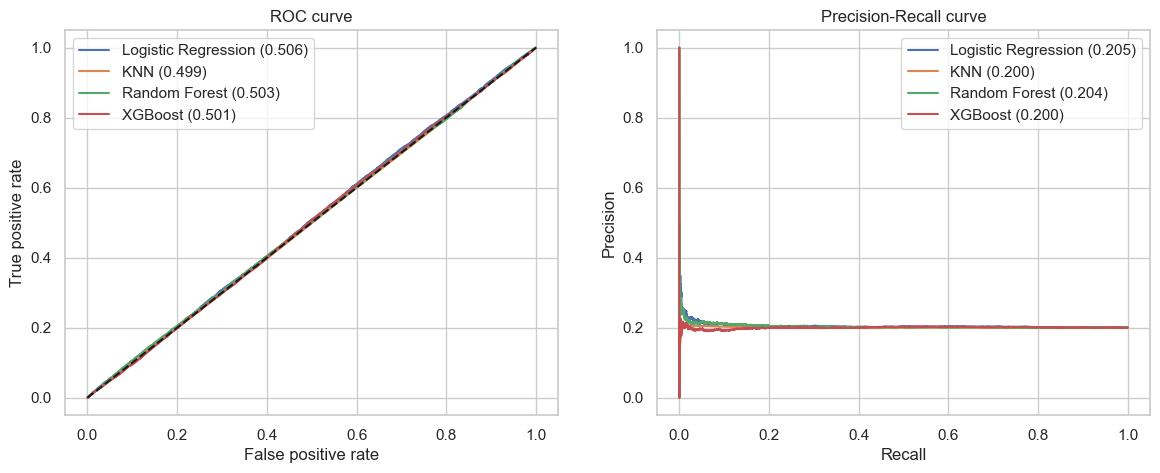

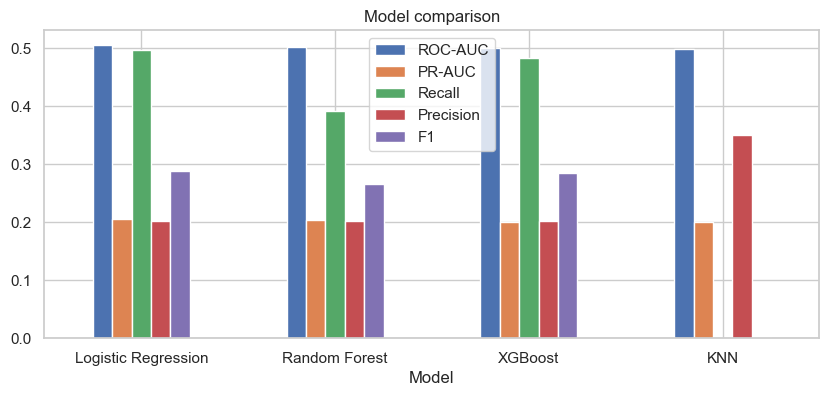

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label="{} ({:.3f})".format(name, roc_auc_score(y_test, proba)))
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label="{} ({:.3f})".format(name, average_precision_score(y_test, proba)))
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate"); axes[0].legend()
axes[1].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision"); axes[1].legend()
plt.show()

comparison[["ROC-AUC", "PR-AUC", "Recall", "Precision", "F1"]].plot(kind="bar", figsize=(10, 4), rot=0, title="Model comparison")
plt.show()

Best threshold: 0.458

Test results of Logistic Regression at this threshold
Precision: 0.200 | Recall: 1.000 | F1: 0.334


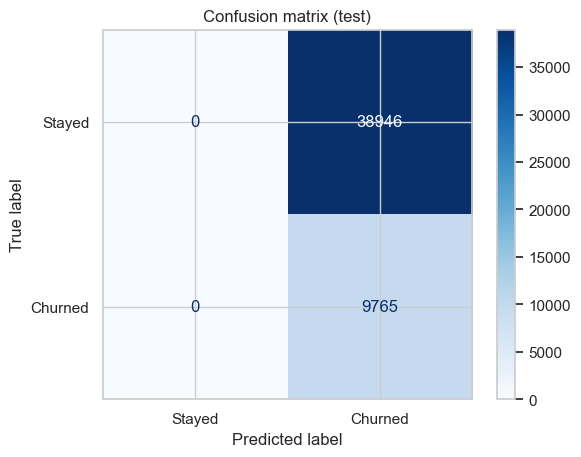

In [34]:
# Decision threshold: 0.5 is not ideal for imbalanced data. Choose the threshold with the best F1,
# using cross-validated predictions on the TRAIN data only (the test set stays untouched).
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
train_proba = cross_val_predict(clone(best_pipe), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, train_proba)
f1_scores = 2 * prec * rec / (prec + rec + 1e-9)
threshold = thr[np.argmax(f1_scores[:-1])]
print("Best threshold:", round(threshold, 3))

test_proba = probas[best_name]
test_pred = (test_proba >= threshold).astype(int)
print("\nTest results of", best_name, "at this threshold")
print("Precision: {:.3f} | Recall: {:.3f} | F1: {:.3f}".format(
    precision_score(y_test, test_pred), recall_score(y_test, test_pred), f1_score(y_test, test_pred)))

ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("Confusion matrix (test)")
plt.show()

## 11. Feature importance

,feature,importance
5,num_dependents,0.0025
12,salary_per_dependent,0.0020
0,telecom_partner,0.0011
3,state,0.0011
4,city,0.0010
7,calls_made,0.0009
9,data_used,0.0008
2,age,0.0004
10,tenure_months,0.0003
8,sms_sent,-0.0001


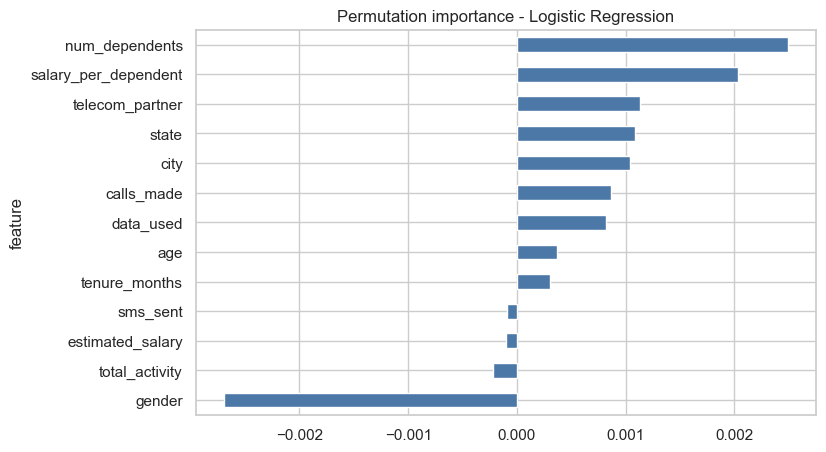

In [36]:
# Permutation importance: how much the PR-AUC drops when a feature is shuffled (works for every model).
sample = X_test.sample(min(10000, len(X_test)), random_state=42)
perm = permutation_importance(best_pipe, sample, y_test.loc[sample.index], scoring="average_precision",
                              n_repeats=3, random_state=42, n_jobs=-1)

importance = pd.DataFrame({"feature": X.columns, "importance": perm.importances_mean}).sort_values("importance", ascending=False)
display(importance.round(4))

importance.sort_values("importance").plot(kind="barh", x="feature", y="importance", figsize=(8, 5), legend=False, color="#4C78A8")
plt.title("Permutation importance - " + best_name)
plt.show()

Features that DECREASE churn (negative coefficient):


cat__state_West Bengal         -0.050
cat__state_Chhattisgarh        -0.046
cat__city_Delhi                -0.026
num__num_dependents            -0.023
cat__state_Tripura             -0.023
cat__state_Kerala              -0.023
num__salary_per_dependent      -0.020
cat__state_Arunachal Pradesh   -0.019
dtype: float64

Features that INCREASE churn (positive coefficient):


cat__state_Jharkhand         0.050
cat__state_Mizoram           0.040
cat__state_Uttarakhand       0.026
cat__state_Karnataka         0.025
cat__state_Rajasthan         0.021
cat__city_Hyderabad          0.018
cat__city_Kolkata            0.017
cat__state_Madhya Pradesh    0.016
dtype: float64

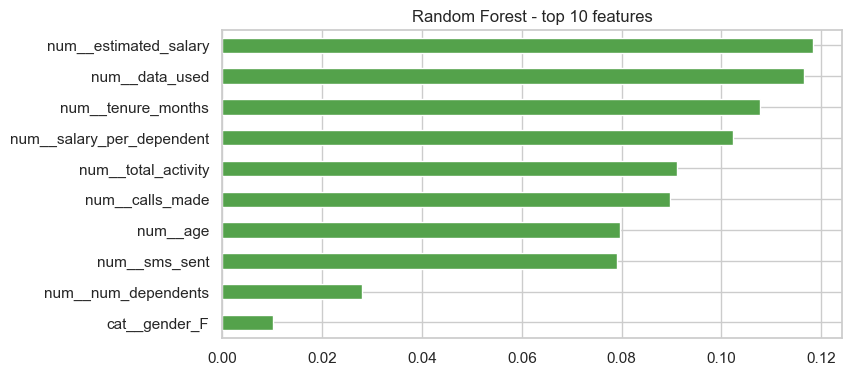

In [37]:
# Direction of effect (does the feature increase or decrease churn?) from Logistic Regression coefficients
lr_pipe = pipelines["Logistic Regression"]
feature_names = lr_pipe["prep"].get_feature_names_out()
coefs = pd.Series(lr_pipe["model"].coef_[0], index=feature_names).sort_values()

print("Features that DECREASE churn (negative coefficient):")
display(coefs.head(8).round(3))
print("Features that INCREASE churn (positive coefficient):")
display(coefs.tail(8).iloc[::-1].round(3))

# Random Forest importance (if available)
rf_pipe = pipelines["Random Forest"]
rf_imp = pd.Series(rf_pipe["model"].feature_importances_, index=rf_pipe["prep"].get_feature_names_out()).sort_values(ascending=False).head(10)
rf_imp.sort_values().plot(kind="barh", figsize=(8, 4), color="#54A24B", title="Random Forest - top 10 features")
plt.show()

## 12. Project goals

This section answers the three goals from the business case.

### Goal 1 - Variables influencing customers to migrate (churn drivers)

In [40]:
top5 = importance.head(5)["feature"].tolist()
print("Top 5 drivers of churn:", top5)

# Numeric drivers: churned vs stayed
numeric_top = [f for f in top5 if f in num_features]
if numeric_top:
    drivers = X.groupby(y)[numeric_top].mean().T
    drivers.columns = ["Stayed (avg)", "Churned (avg)"]
    drivers["Difference %"] = ((drivers["Churned (avg)"] / drivers["Stayed (avg)"] - 1) * 100).round(1)
    display(drivers.round(2))

# Categorical drivers: churn rate for each category
for f in [f for f in top5 if f in cat_cols]:
    rate = (data.groupby(f)["churn"].mean() * 100).sort_values(ascending=False).round(2)
    print("\nChurn % by", f, "(overall:", round(y.mean() * 100, 2), "%)")
    display(rate.head(8).to_frame("churn %"))

Top 5 drivers of churn: ['num_dependents', 'salary_per_dependent', 'telecom_partner', 'state', 'city']


,Stayed (avg),Churned (avg),Difference %
num_dependents,2.00,1.99,-0.4
salary_per_dependent,38885.89,38771.42,-0.3



Churn % by telecom_partner (overall: 20.05 %)


,churn %
telecom_partner,
Airtel,20.37
Reliance Jio,20.02
Vodafone,19.95
BSNL,19.86



Churn % by state (overall: 20.05 %)


,churn %
state,
Jharkhand,21.12
Karnataka,20.71
Mizoram,20.65
Uttarakhand,20.42
Himachal Pradesh,20.41
Madhya Pradesh,20.38
Assam,20.30
Odisha,20.25



Churn % by city (overall: 20.05 %)


,churn %
city,
Hyderabad,20.42
Mumbai,20.16
Kolkata,20.16
Bangalore,20.05
Chennai,19.76
Delhi,19.75


### Goal 2 - Churn risk scores (0 to 100)

,customers,actual_churn_rate
risk_band,,
High,243549,0.20
Medium,4,0.25


,customers,churners,churn_rate,lift,cumulative % churners captured
decile,,,,,
1,24356,4909,0.202,1.005,10.054
2,24355,4964,0.204,1.017,20.220
3,24355,4812,0.198,0.986,30.076
4,24355,4940,0.203,1.012,40.193
5,24356,4893,0.201,1.002,50.214
6,24355,4909,0.202,1.005,60.268
7,24355,4853,0.199,0.994,70.207
8,24355,4834,0.198,0.990,80.107
9,24355,4870,0.200,0.997,90.081


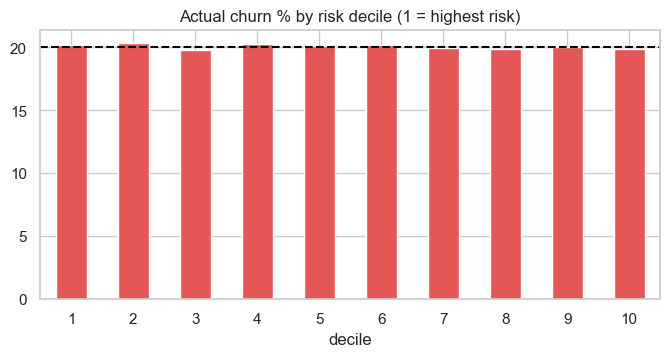

In [42]:
# Score every customer using cross-validated probabilities (each customer is scored by a model that did not see them)
X_all = X.copy()
X_all[num_features] = cap_outliers(X_all[num_features], lower, upper)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
all_proba = cross_val_predict(clone(best_pipe), X_all, y, cv=cv, method="predict_proba")[:, 1]

scores = pd.DataFrame({"customer_id": df["customer_id"], "telecom_partner": df["telecom_partner"],
                       "state": df["state"], "churn_risk_score": (all_proba * 100).round(1),
                       "actual_churn": y})

# Risk band: High = above the flag threshold, Medium = above half of it, Low = the rest
flag_score = threshold * 100
scores["risk_band"] = np.where(scores["churn_risk_score"] >= flag_score, "High",
                        np.where(scores["churn_risk_score"] >= flag_score / 2, "Medium", "Low"))

display(scores.groupby("risk_band").agg(customers=("customer_id", "count"),
                                        actual_churn_rate=("actual_churn", "mean")).round(3))

# Decile table: customers sorted from highest to lowest risk
scores["decile"] = pd.qcut(scores["churn_risk_score"].rank(method="first", ascending=False), 10, labels=range(1, 11))
decile = scores.groupby("decile").agg(customers=("customer_id", "count"), churners=("actual_churn", "sum"),
                                      churn_rate=("actual_churn", "mean"))
decile["lift"] = decile["churn_rate"] / y.mean()
decile["cumulative % churners captured"] = decile["churners"].cumsum() / decile["churners"].sum() * 100
display(decile.round(3))

(decile["churn_rate"] * 100).plot(kind="bar", color="#E45756", figsize=(8, 3.5), rot=0)
plt.axhline(y.mean() * 100, color="black", linestyle="--")
plt.title("Actual churn % by risk decile (1 = highest risk)")
plt.show()

### Goal 3 - `CHURN_FLAG` (YES = 1 / NO = 0) for campaigns and customer care

In [44]:
scores["CHURN_FLAG"] = (all_proba >= threshold).astype(int)
print("Customers flagged YES:", scores["CHURN_FLAG"].sum(), "of", len(scores),
      "({:.1%})".format(scores["CHURN_FLAG"].mean()))
print("Precision: {:.3f} | Recall: {:.3f}".format(precision_score(y, scores["CHURN_FLAG"]), recall_score(y, scores["CHURN_FLAG"])))
display(pd.crosstab(scores["actual_churn"], scores["CHURN_FLAG"], rownames=["Actual churn"], colnames=["CHURN_FLAG"]))

# Ticket priority for customer care
top10_cut = scores["churn_risk_score"].quantile(0.90)
def ticket_priority(row):
    if row["CHURN_FLAG"] == 1 and row["churn_risk_score"] >= top10_cut:
        return "P1 - Critical"
    if row["CHURN_FLAG"] == 1:
        return "P2 - High"
    if row["risk_band"] == "Medium":
        return "P3 - Watch"
    return "P4 - Normal"
scores["ticket_priority"] = scores.apply(ticket_priority, axis=1)
display(scores.groupby("ticket_priority").agg(customers=("customer_id", "count"),
                                              actual_churn_rate=("actual_churn", "mean")).round(3))

# Customers for the retention email campaign
campaign = scores[scores["CHURN_FLAG"] == 1].sort_values("churn_risk_score", ascending=False)
campaign = campaign[["customer_id", "telecom_partner", "state", "churn_risk_score", "risk_band", "ticket_priority"]]
print("\nEmail campaign list:", len(campaign), "customers")
campaign.head(10)

Customers flagged YES: 243550 of 243553 (100.0%)
Precision: 0.200 | Recall: 1.000


CHURN_FLAG,0,1
Actual churn,,
0,2,194724
1,1,48826


,customers,actual_churn_rate
ticket_priority,,
P1 - Critical,27161,0.201
P2 - High,216389,0.200
P3 - Watch,3,0.333



Email campaign list: 243550 customers


,customer_id,telecom_partner,state,churn_risk_score,risk_band,ticket_priority
236286,236287,Airtel,Karnataka,54.4,High,P1 - Critical
57218,57219,Airtel,Jharkhand,54.3,High,P1 - Critical
227735,227736,Airtel,Jharkhand,54.3,High,P1 - Critical
188628,188629,Airtel,Karnataka,54.2,High,P1 - Critical
241806,241807,Airtel,Jharkhand,54.2,High,P1 - Critical
112273,112274,Airtel,Jharkhand,54.2,High,P1 - Critical
126584,126585,Airtel,Jharkhand,54.2,High,P1 - Critical
53477,53478,Airtel,Jharkhand,54.1,High,P1 - Critical
106004,106005,Airtel,Jharkhand,54.0,High,P1 - Critical
196150,196151,Airtel,Jharkhand,54.0,High,P1 - Critical


In [45]:
# Save the results and the model
import joblib

scores.drop(columns="decile").to_csv("churn_scored_customers.csv", index=False)
campaign.to_csv("email_campaign_targets.csv", index=False)

final_model = clone(best_pipe).fit(pd.concat([X_train, X_test]), pd.concat([y_train, y_test]))   # refit on all data
joblib.dump({"model": final_model, "threshold": threshold, "lower": lower, "upper": upper,
             "features": list(X.columns)}, "churn_model.joblib")

try:
    with pd.ExcelWriter("churn_project_goals.xlsx") as writer:
        importance.to_excel(writer, sheet_name="Goal1_Churn_Drivers", index=False)
        decile.reset_index().to_excel(writer, sheet_name="Goal2_Risk_Deciles", index=False)
        scores.drop(columns="decile").to_excel(writer, sheet_name="Goal2_Risk_Scores", index=False)
        campaign.to_excel(writer, sheet_name="Goal3_Churn_Flag_YES", index=False)
        comparison.reset_index().to_excel(writer, sheet_name="Model_Comparison", index=False)
    print("Saved: churn_project_goals.xlsx, churn_scored_customers.csv, email_campaign_targets.csv, churn_model.joblib")
except ImportError:
    print("Saved CSV files and model. For the Excel file run: pip install openpyxl")

Saved: churn_project_goals.xlsx, churn_scored_customers.csv, email_campaign_targets.csv, churn_model.joblib


## Summary

In [47]:
print("Best model       :", best_name)
print("ROC-AUC / PR-AUC :", round(comparison.loc[best_name, "ROC-AUC"], 3), "/", round(comparison.loc[best_name, "PR-AUC"], 3))
print("Top churn drivers:", ", ".join(importance.head(5)["feature"]))
print("Top-10% riskiest customers churn at {:.1f}x the average rate".format(decile.loc[1, "lift"]))
print("Customers flagged CHURN_FLAG = YES:", scores["CHURN_FLAG"].sum())

Best model       : Logistic Regression
ROC-AUC / PR-AUC : 0.506 / 0.205
Top churn drivers: num_dependents, salary_per_dependent, telecom_partner, state, city
Top-10% riskiest customers churn at 1.0x the average rate
Customers flagged CHURN_FLAG = YES: 243550


### Recommended actions
* **Email campaign:** send offers to `CHURN_FLAG = 1` customers, highest `churn_risk_score` first. Match the offer to the top drivers above (e.g. partner-specific or usage-based offers) instead of one blanket discount.
* **Customer care:** treat `P1` and `P2` customers as priority - tag their tickets high priority and resolve quickly.
* **Check the model quality:** if ROC-AUC is close to 0.50, the available columns carry little information about churn. The fix is richer data (billing, complaints, plan type, recharge history), not a more complex model.
* **Keep it fresh:** re-score customers every month and retrain every quarter.